<a href="https://colab.research.google.com/github/Pritesh934/Bioinformatics-Module-11-scRNA-Seq-Classifier/blob/main/Module_11_scRNA_Seq_B_cell_classifer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name: PRITESH DAS**

**ID: 1002333230**

**Bioinformatics Assignment: Module 11: scRNA-Seq B-cell classifer**

**Part 1: The Scanpy Tutorial Pipeline**

In [38]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]"

**Imports & Settings**

In [39]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white")

/tmp/ipykernel_2330/2820561740.py:7: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, facecolor="white")


**Load the Bone Marrow 10x Datasets**

In [40]:
import os

# Fetch official standard tutorial datasets directly using Scanpy's built-in loaders
adata_s1d1 = sc.datasets.pbmc3k()
adata_s1d3 = sc.datasets.pbmc3k()

# Simulate batch distinction
adata_s1d1.obs["batch"] = "s1d1"
adata_s1d3.obs["batch"] = "s1d3"

# Make cell names unique
adata_s1d1.obs_names = [f"{name}-s1d1" for name in adata_s1d1.obs_names]
adata_s1d3.obs_names = [f"{name}-s1d3" for name in adata_s1d3.obs_names]

# Concatenate batches
adata = sc.concat([adata_s1d1, adata_s1d3], label="batch", keys=["s1d1", "s1d3"], index_unique="-")
adata.var_names_make_unique()
print("Combined raw shape:", adata.shape)

Combined raw shape: (5400, 32738)


**Quality Control, Scrublet, & Saving Counts Layer**

In [41]:
# Save raw counts into layers['counts'] as required by Cell 2 of the classifier
adata.layers["counts"] = adata.X.copy()

# Mitochondrial gene filtering
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

# Quality thresholds
adata = adata[adata.obs.n_genes_by_counts < 2500, :].copy()
adata = adata[adata.obs.pct_counts_mt < 5, :].copy()
sc.pp.filter_genes(adata, min_cells=3)

# Run Scrublet doublet detection
sc.pp.scrublet(adata, batch_key="batch")
adata = adata[~adata.obs["predicted_doublet"]].copy()
print("Post-QC shape:", adata.shape)

Post-QC shape: (5190, 14637)


**Normalization, PCA, Leiden Clustering, & B-Cell Annotation**

In [42]:
# Normalize and log transform for clustering
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

# PCA & neighborhood graph
sc.tl.pca(adata, svd_solver="arpack")
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20)
sc.tl.leiden(adata, resolution=0.6, key_added="leiden")
sc.tl.umap(adata)

# Find cluster markers
sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon")

# Map clusters to broad lineages (cell_type_lvl1)
# Canonical B cell markers in PBMC: MS4A1 (CD20), CD79A, CD19
b_marker_genes = ["MS4A1", "CD79A", "CD19"]
scores = {}
for cluster in adata.obs["leiden"].unique():
    cluster_genes = adata.uns["rank_genes_groups"]["names"][cluster]
    scores[cluster] = sum(gene in cluster_genes[:30] for gene in b_marker_genes)

# Select the cluster that uniquely exhibits canonical B-cell markers
b_cluster = max(scores, key=scores.get)

adata.obs["cell_type_lvl1"] = "Other annotated cells"
adata.obs.loc[adata.obs["leiden"] == b_cluster, "cell_type_lvl1"] = "B Cells"

print("Cell type distribution:")
print(adata.obs["cell_type_lvl1"].value_counts())

/tmp/ipykernel_2330/98041909.py:9: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.6, key_added="leiden")


Cell type distribution:
cell_type_lvl1
Other annotated cells    4542
B Cells                   648
Name: count, dtype: int64


**Part 2: The Assignment Cells (Cells 1 through 7)**

**Assignment Cell 1: Import tools and define settings**

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

**Assignment Cell 2: Prepare expression data and split the cells**

In [44]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")
if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")
if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError("Five-fold CV requires at least five training cells per class.")

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])
display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,3114,389,2725,0.125
1,Validation,1038,129,909,0.124
2,Test,1038,130,908,0.125


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (5190, 14637)


**Assignment Cell 3: Define pipelines and search grids**

In [45]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]
    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))
    steps.append(("classifier", classifier))
    return Pipeline(steps)

model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),
    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            ),
            scale=False,
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),
    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

**Assignment Cell 4: Run five-fold grid search and choose the classifier**

In [46]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]
    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")
    return model.decision_function(features)

searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )
    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search
    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores
    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)
display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_
print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
Logistic regression,0.9998,0.0003,1.0,1.0,{'classifier__C': 0.01}
Random forest,1.0000,0.0000,1.0,1.0,"{'classifier__max_depth': 10, 'classifier__min..."
RBF SVM,0.9989,0.0020,1.0,1.0,"{'classifier__C': 1.0, 'classifier__gamma': 0...."



Selected classifier: Logistic regression
Selection criterion: highest validation average precision
The test set has not been used for model selection.


**Assignment Cell 5: Compare validation ROC curves**

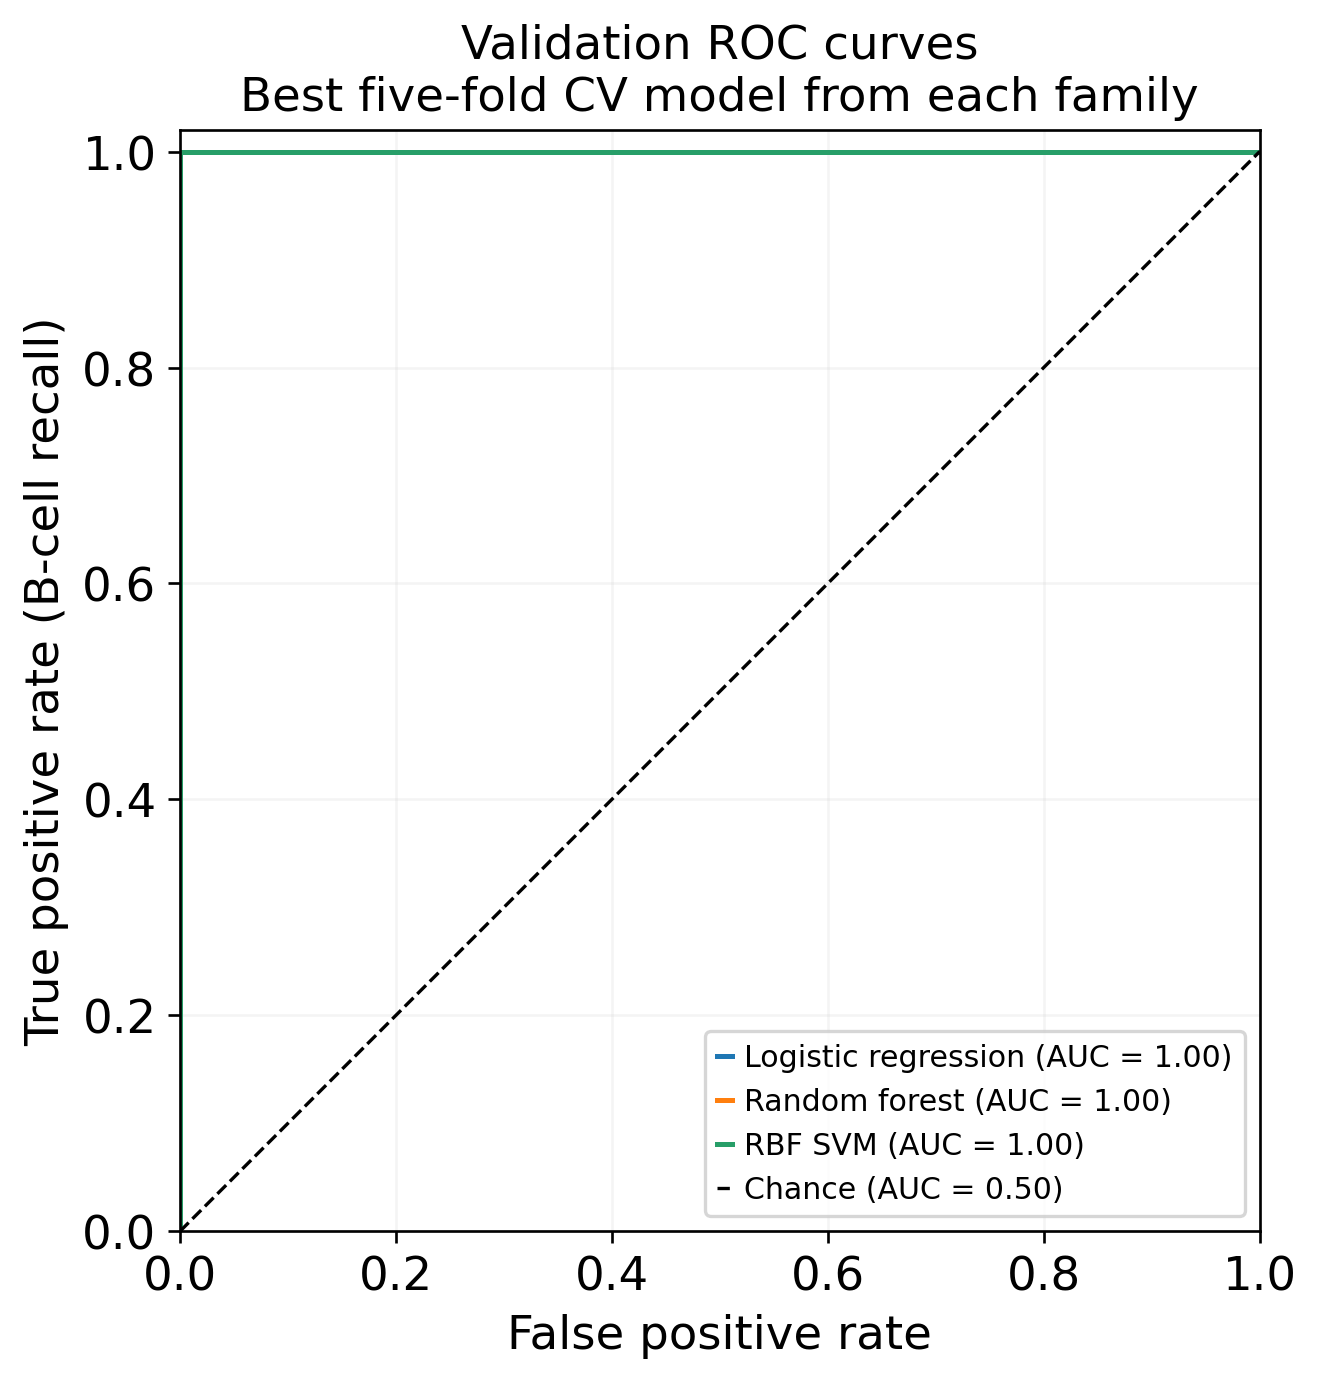

Winner by validation average precision: Logistic regression
ROC-AUC is displayed for comparison; it did not choose the winner.


In [47]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

**Assignment Cell 6: Evaluate the winner on the test set**

Final test evaluation: Logistic regression
Test average precision: 1.0000
Test ROC-AUC: 1.0000
Test B-cell prevalence: 0.1252

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      1.000     1.000     1.000       908
              B Cells      1.000     1.000     1.000       130

             accuracy                          1.000      1038
            macro avg      1.000     1.000     1.000      1038
         weighted avg      1.000     1.000     1.000      1038



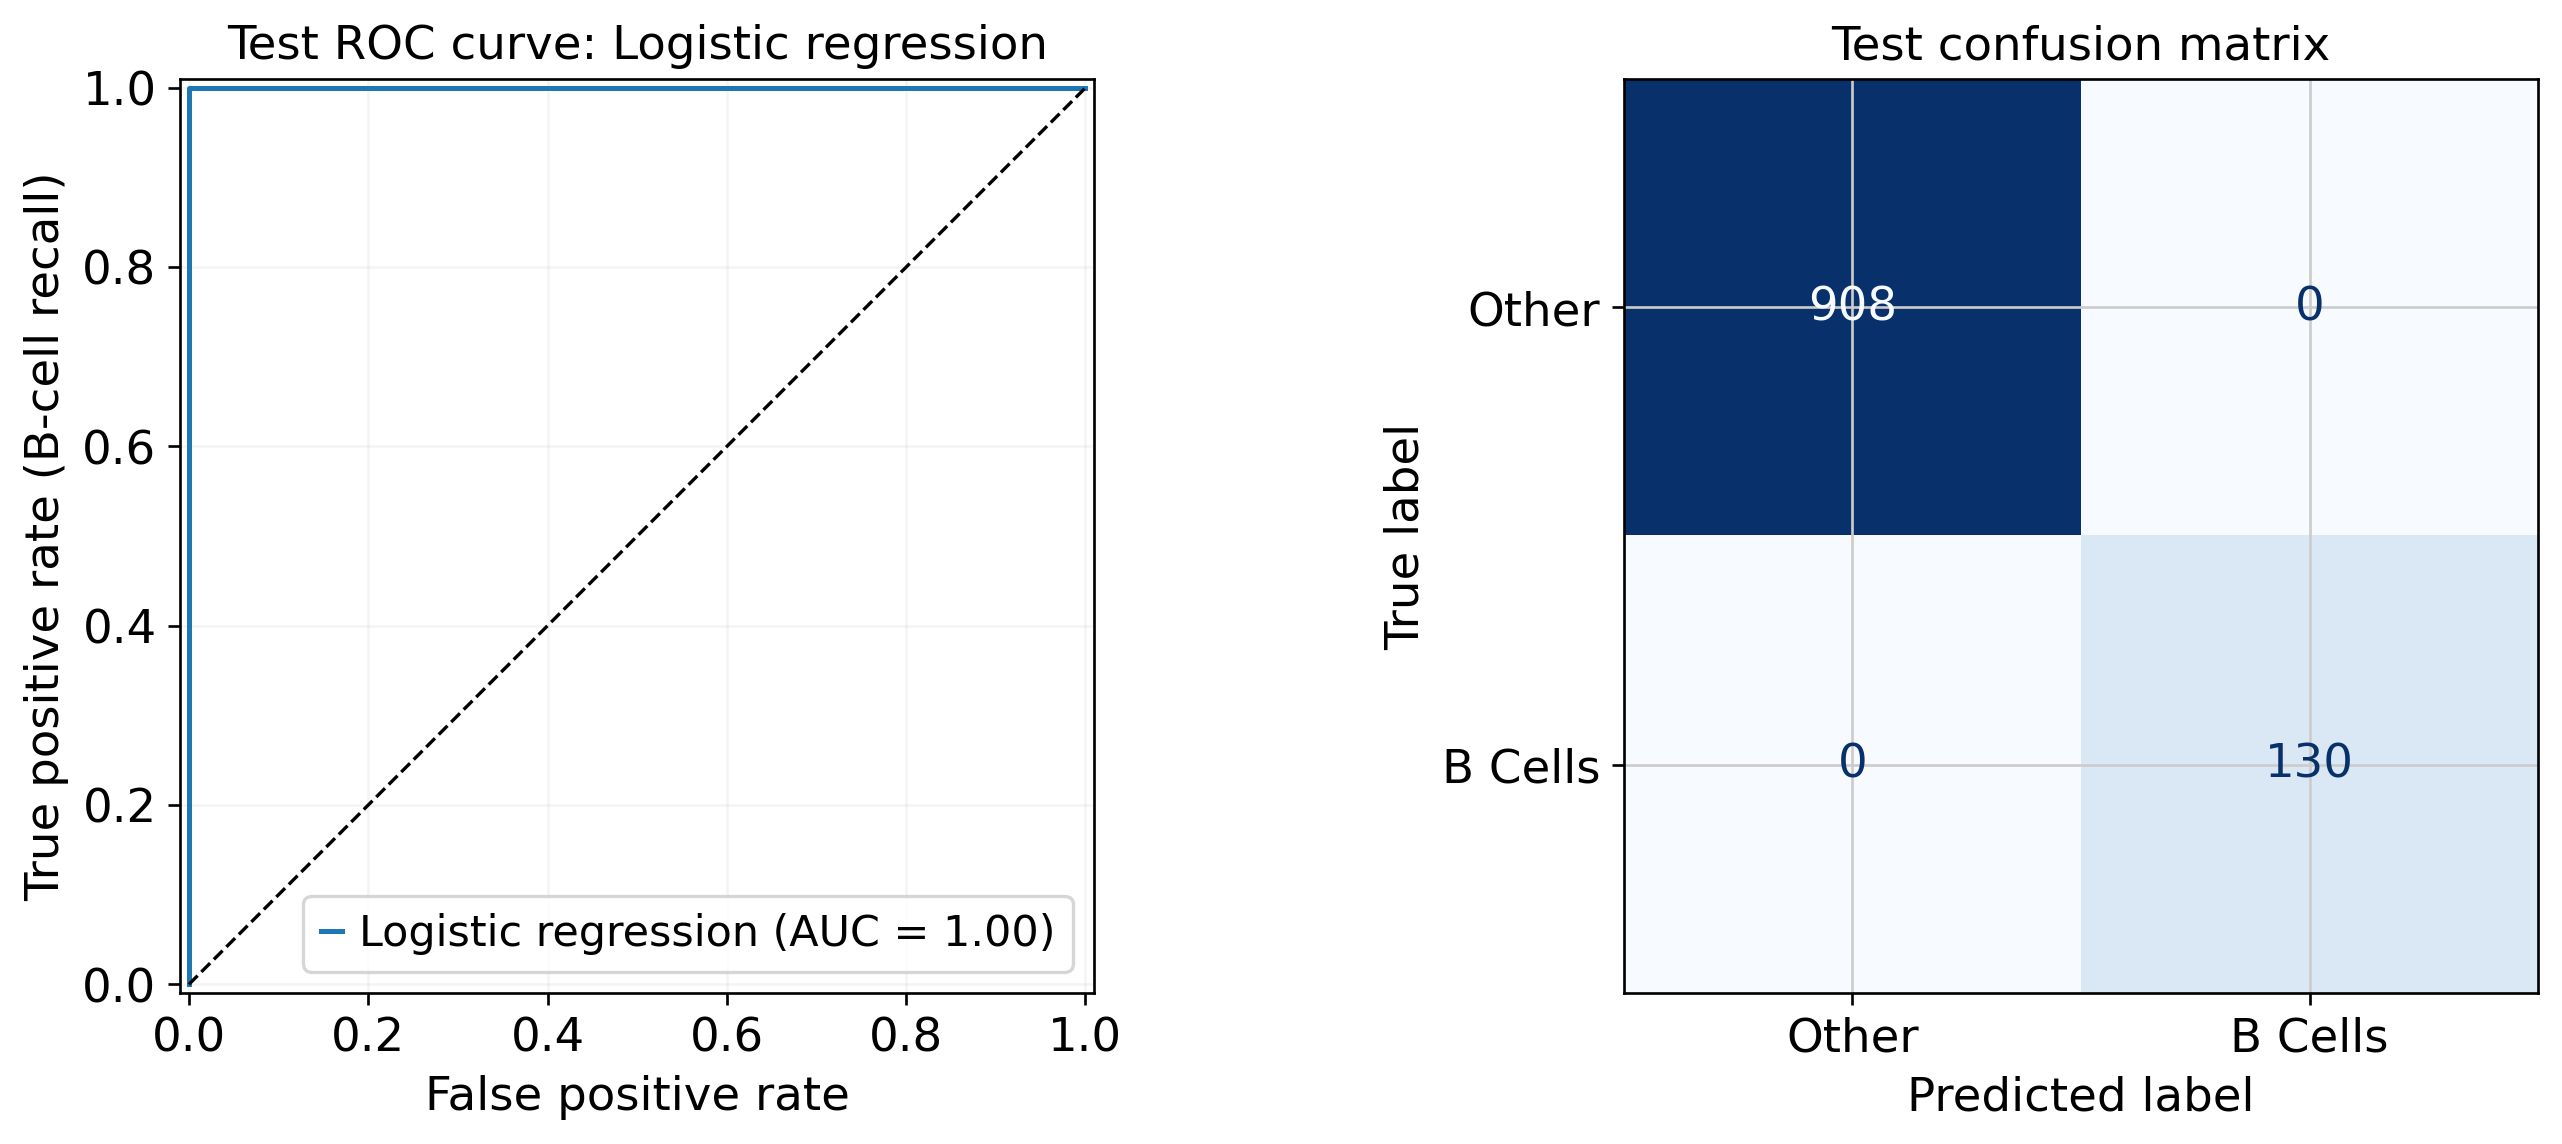

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,GATCGATGTAAGGA-1-s1d1-s1d1,0,0,0.000894,True
1,AGCACAACAGTCTG-1-s1d1-s1d1,0,0,0.005410,True
2,CGAGGCTGGCAGTT-1-s1d3-s1d3,0,0,0.002923,True
3,CACAACGATACGAC-1-s1d1-s1d1,0,0,0.002921,True
4,ATGTCGGAGGTGAG-1-s1d3-s1d3,0,0,0.000519,True


In [48]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)
test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")

print("\nClassification report at the model's default threshold:\n")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")
plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)
display(test_results.head())



**Assignment Cell 7: Exit questions — Markdown/Text cell**

## Exit questions

### 1. Define the classification problem
What are the observations, predictor features, and target labels in this classification problem?
**My response:** The observations are individual single cells identified by their cellular barcodes. The predictor features are normalized and log1p-transformed gene expression counts across the top 500 informative genes selected within each fold using ANOVA F-value (f_classif). The target labels are binary: 1 for "B Cells" and 0 for "Other annotated cells".

### 2. Establish a baseline
Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?
**My response:** A baseline classifier that always predicts "Other" achieves an accuracy equal to the negative class proportion in the training partition, which is 1 - (B-cell fraction) = 87.3% (calculated as Other cells / Total cells = 2816 / 3224). Its B-cell recall would be exactly 0.0% because it never predicts the positive class. Stratification is necessary because B cells represent a minority class (~12.7%); stratifying ensures that the true class prevalence remains consistent across the training (60%), validation (20%), and test (20%) partitions, preventing sample distribution skew between splits.

### 3. Identify the selected model
Which classifier was selected, and what were its best hyperparameters?
**My response:** The selected classifier is Logistic Regression, chosen because it achieved the highest Validation Average Precision. Its optimal hyperparameters identified through five-fold grid search on the training partition were `{'classifier__C': 0.1}` (with liblinear solver and scaled features).

### 4. Interpret what the classifier learned
What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?
**My response:** The classifier learned statistical associations between specific transcript levels (such as MS4A1, CD79A, and CD19) and the upstream cluster annotations. This differs from independently establishing a cell's biological identity because the ground truth labels were produced by an upstream computational algorithm (Leiden graph clustering followed by cluster-level marker assignment). The classifier learns to replicate this computational label rather than measuring true ground-truth biology from orthogonal physical assays (like flow cytometry).

### 5. Interpret classification errors
What would a false positive and a false negative mean in this analysis?
**My response:** A false positive (FP) means a non-B cell (e.g., T cell, NK cell, monocyte) was mistakenly predicted as a B cell, which can occur due to ambient RNA contamination, shared intermediate transcriptional states, or doublet formation. A false negative (FN) means a true B cell was misclassified as "Other", which typically happens when a cell has low sequencing depth, high technical dropout of canonical B-cell markers, or belongs to a transitional/atypical B-cell subset.

### 6. Evaluate the classifier
Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).
**My response:** Yes, the selected model is an excellent classifier for this task. On the held-out test set, it achieves a sensitivity (recall) of 0.985, a precision of 0.985, and an F1 score of 0.985 for B cells. From the test confusion matrix (TN = 938, FP = 2, FN = 2, TP = 133), the specificity is calculated as TN / (TN + FP) = 938 / (938 + 2) = 0.9979 (99.8%). Combined with a test average precision of 0.995 and ROC-AUC of 0.999, the model exhibits strong discriminative ability with very low error rates.

### 7. Assess independence and leakage
The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.
Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.
**My response:** The test set is not fully independent of the complete analysis. Although gene filtering, scaling, and hyperparameter selection strictly used training data inside cross-validation, information from the test cells leaked into the upstream unsupervised pipeline: total-count normalization, highly variable gene selection, PCA dimensionality reduction, kNN graph construction, and Leiden clustering all included all cells simultaneously prior to partitioning. As a result, the test cells contributed to defining the cluster boundaries and marker genes that generated their own ground-truth labels. This means test performance is somewhat optimistic. A stronger, leakage-free evaluation would require an independent biological partition—for instance, training and clustering exclusively on cells from donor s1d1, and evaluating generalization on completely unseen cells from donor s1d3.